In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Run the following commands for generating the data of Figure 5.

```bash
python simulations/code_capacity/logical_error_rate_ism.py --distances 5 11 17 23 29 35 --error-rates 0.05 0.50 0.02 --shots 50000 --no-post-processing --output simulations/code_capacity/Fig-5-LER/data/ism.csv

python simulations/code_capacity/logical_error_rate_ism.py --distances 5 11 17 23 29 35 --error-rates 0.05 0.50 0.02 --shots 50000 --output simulations/code_capacity/Fig-5-LER/data/ism_pp.csv

python simulations/code_capacity/logical_error_rate_gsm.py --distances 5 11 17 23 29 35 --error-rates 0.05 0.50 0.02 --shots 50000 --no-post-processing --output simulations/code_capacity/Fig-5-LER/data/gsm.csv

python simulations/code_capacity/logical_error_rate_gsm.py --distances 5 11 17 23 29 35 --error-rates 0.05 0.50 0.02 --shots 50000 --output simulations/code_capacity/Fig-5-LER/data/gsm_pp.csv

```



In [2]:
# import data from csv file
data_ISM    = pd.read_csv(Path("./data") / "ism.csv")
data_ISM_PP = pd.read_csv(Path("./data") / "ism_pp.csv")

data_GSM    = pd.read_csv(Path("./data") / "gsm.csv")
data_GSM_PP = pd.read_csv(Path("./data") / "gsm_pp.csv")

In [3]:
def find_intersections(df, x_col="p_phys", y_col="p_log", dist_col="distance"):
    """
    Crossing points of the logical-error-rate curves of each pair of subsequent distances.

    Each curve is linearly interpolated in (p_phys, log p_log), matching the log-scale plot. For each
    pair (d_i, d_{i+1}) the first crossing where the larger distance goes from below to above the
    smaller one is returned (nan if the curves don't cross in the sampled range). Points with
    p_log == 0 are ignored, since they have no logarithm.

    Returns:
        x_dot, y_dot: lists with one crossing per pair of subsequent distances.
    """
    distances = sorted(df[dist_col].unique())
    x_dot, y_dot = [], []
    for d_small, d_large in zip(distances[:-1], distances[1:]):
        a = df[(df[dist_col] == d_small) & (df[y_col] > 0)].sort_values(x_col)
        b = df[(df[dist_col] == d_large) & (df[y_col] > 0)].sort_values(x_col)

        # common grid on the overlapping range of both curves
        lo = max(a[x_col].min(), b[x_col].min())
        hi = min(a[x_col].max(), b[x_col].max())
        x = np.union1d(a[x_col], b[x_col])
        x = x[(x >= lo) & (x <= hi)]

        log_ya = np.interp(x, a[x_col], np.log(a[y_col]))
        log_yb = np.interp(x, b[x_col], np.log(b[y_col]))
        diff = log_ya - log_yb  # > 0 below threshold (larger distance is better)

        x_cross, y_cross = np.nan, np.nan
        for i in range(len(x) - 1):
            if diff[i] >= 0 and diff[i + 1] < 0:
                t = diff[i] / (diff[i] - diff[i + 1])
                x_cross = x[i] + t * (x[i + 1] - x[i])
                y_cross = np.exp(log_ya[i] + t * (log_ya[i + 1] - log_ya[i]))
                break
        x_dot.append(x_cross)
        y_dot.append(y_cross)
    return x_dot, y_dot

# Figure 5:

In [4]:
def plot_logical_error_rate(df, ax, show_intersections=True, save_path=None):
    for d in df['distance'].unique():
        data = df[df['distance'] == d]
        ax.plot(data['p_phys'], data['p_log'], label='d={}'.format(d), marker='o', linestyle='solid',
            linewidth=4, markersize=10)

    # crossing points of subsequent distances, marked with a black dot and a dashed vertical line
    if show_intersections:
        x_dot, y_dot = find_intersections(df)
        for x_cross, y_cross in zip(x_dot, y_dot):
            if np.isnan(x_cross):
                continue
            ax.scatter(x_cross, y_cross, marker='o', color='black', s=250, zorder=3)
            ax.axvline(x=x_cross, color='black', linestyle='dashed', linewidth=2, alpha=0.7)

    ax.legend(loc='lower right', prop={'size': 28})
    plt.xticks(fontsize=28)
    plt.yticks(fontsize=28)
    plt.xlabel('Physical error probability', size=28)
    plt.ylabel('Code failure rate', size=28)
    plt.xlim(0.05, 0.5)
    plt.ylim(7.0E-3, 1.1)
    plt.yscale('log')
    # Thicker box around plot (spines)
    for spine in ax.spines.values():
        spine.set_linewidth(3)  # Adjust thickness as needed
    # Thicker major ticks
    ax.tick_params(axis='both', which='major', width=3, length=12)  # length is optional
    # Thicker minor ticks
    ax.tick_params(axis='both', which='minor', width=1.5, length=8)  # Adjust as needed
    if save_path is not None:
        ax.figure.savefig(save_path, format='pdf', bbox_inches='tight')
    plt.show()


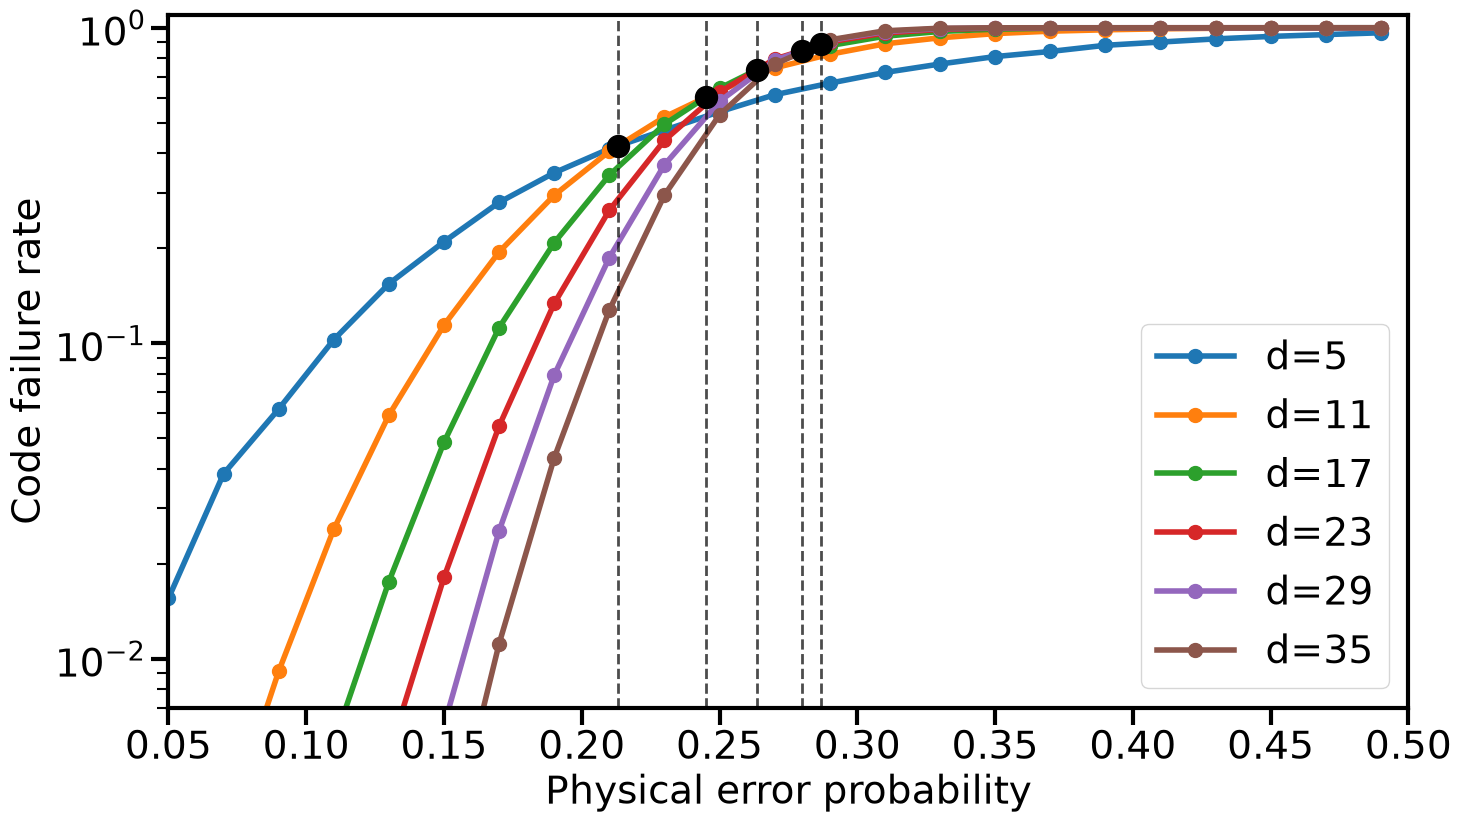

In [5]:
fig, ax = plt.subplots(figsize=(16, 9))
plot_logical_error_rate(data_GSM, ax, save_path='Fig-LER-ideal-b-new.pdf')

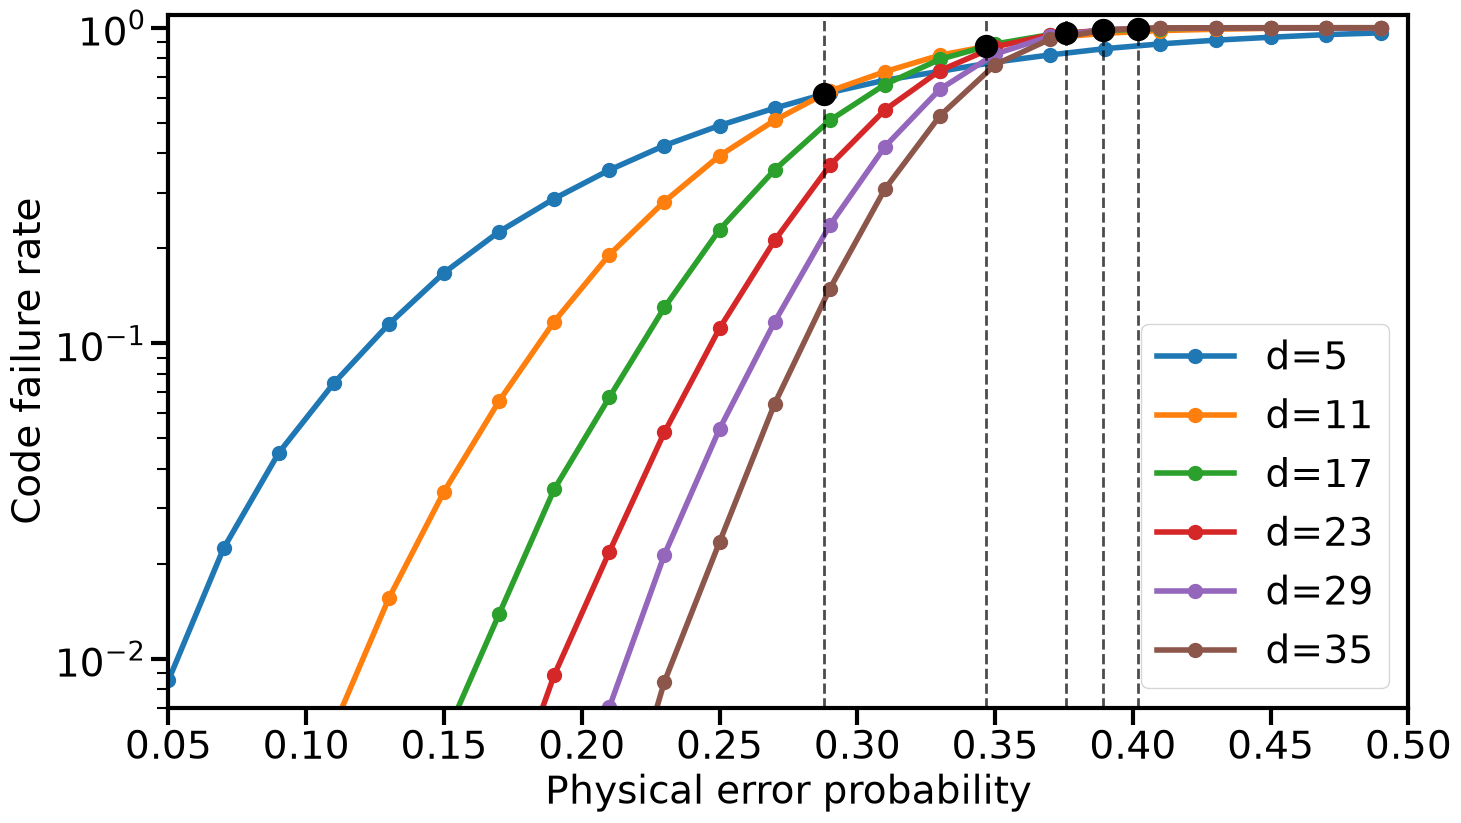

In [6]:
fig, ax = plt.subplots(figsize=(16, 9))
plot_logical_error_rate(data_GSM_PP, ax, save_path='Fig-LER-ideal-a-new.pdf')

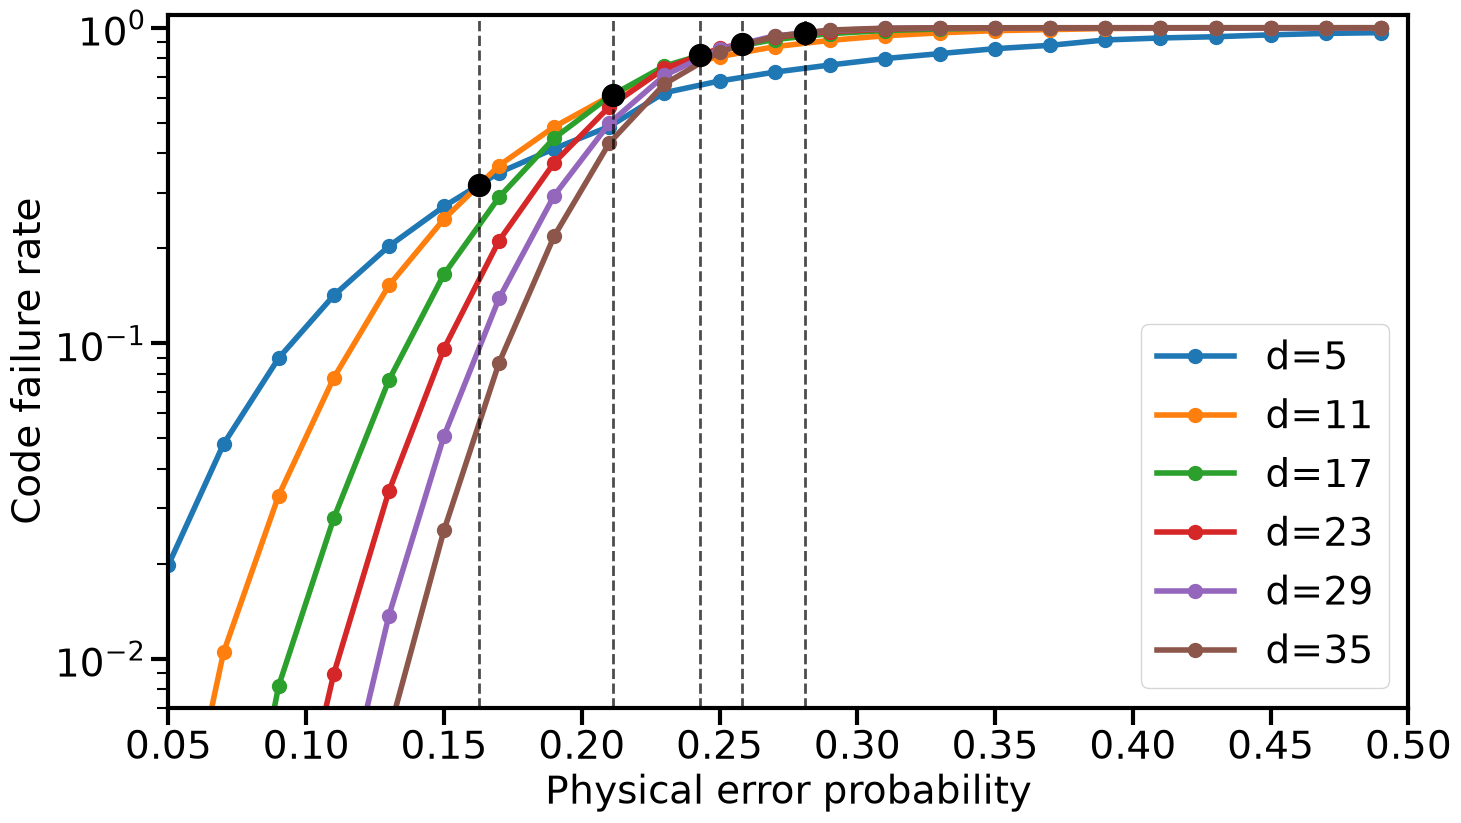

In [7]:
fig, ax = plt.subplots(figsize=(16, 9))
plot_logical_error_rate(data_ISM, ax)

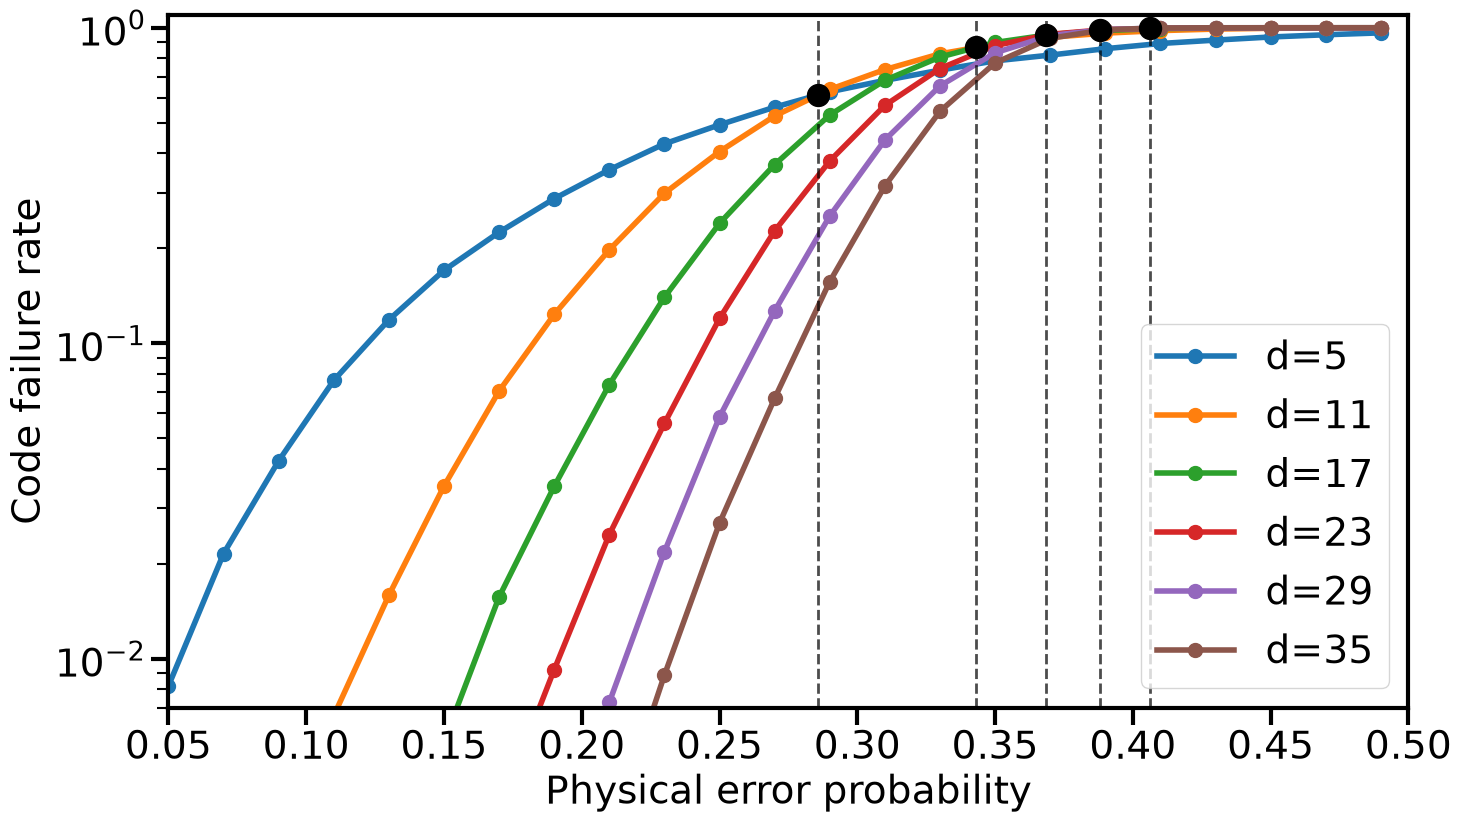

In [8]:
fig, ax = plt.subplots(figsize=(16, 9))
plot_logical_error_rate(data_ISM_PP, ax)